# SIngle route query

Note in .db and .csv default is_realtime column is 1 for True, 0 for False

Note in routes: Usually routenumbers ending in N are almost identical to the route with same number without N, just operated during the night, for example 500 - 500N. 
Other letters may also appear but are more rare/less operated.
Check trip counts in cell 11

In [9]:
import sqlite3
from pathlib import Path
import pandas as pd
import numpy as np

DB_PATH = Path("route_all.db")   

if not DB_PATH.exists():
    raise FileNotFoundError(f"{DB_PATH.resolve()} not found. Fix DB_PATH or move the notebook next to the file.")

conn = sqlite3.connect(DB_PATH)

# One-off: makes route lookups fast instead of scanning every row.
conn.execute("CREATE INDEX IF NOT EXISTS idx_route ON stoptimes(route)")
conn.commit()

## Overview of the database

first and last day in YYYYMMDD format, share realtime *100 percentage of realtime rows

In [10]:
overview = pd.read_sql_query(
    """
    SELECT COUNT(*)                    AS rows,
           COUNT(DISTINCT route)       AS routes,
           COUNT(DISTINCT service_date) AS days,
           MIN(service_date)           AS first_day,
           MAX(service_date)           AS last_day,
           ROUND(AVG(is_realtime), 3)  AS share_realtime
    FROM stoptimes
    """,
    conn,
)
overview

,rows,routes,days,first_day,last_day,share_realtime
0,4222845,391,5,20261010,20261014,0.491


In [32]:
routes = pd.read_sql_query(
    """
    SELECT route, COUNT(*) AS rows, ROUND(AVG(is_realtime), 3) AS share_realtime
    FROM stoptimes
    GROUP BY route
    ORDER BY rows DESC
    """,
    conn,
)
routes.head(20)

,route,rows,share_realtime
0,69,72668,0.470
1,570,64995,0.424
2,560,60885,0.568
3,79,57105,0.630
4,71,56956,0.454
5,561,55963,0.427
6,57,53600,0.620
7,52,52359,0.625
8,520,51689,0.567
9,300,51114,0.431


## Load the route


shows number of unique trips


In [69]:
ROUTE = "506" 
ONLY_REALTIME = True #If you want rows where is_realtime = False change ONLY_REALTIME = False
is_realtime_boolean = False #Change is_realtime from 1/0 to True/False

query = """
    SELECT service_date, route, trip_id, stop_position, stop_id,
           scheduled_departure_sec, delay_seconds, is_realtime
    FROM stoptimes
    WHERE route = ?
"""
if ONLY_REALTIME:
    query += " AND is_realtime = 1"
query += " ORDER BY service_date, trip_id, stop_position"

df = pd.read_sql_query(query, conn, params=(ROUTE,))
print(f"{len(df):,} rows, {df['trip_id'].nunique():,} trips for route {ROUTE}")

if is_realtime_boolean:
    df = df.replace({'is_realtime': {1: True}})
    df = df.replace({'is_realtime': {0: False}})


df.head()

21,461 rows, 505 trips for route 506


,service_date,route,trip_id,stop_position,stop_id,scheduled_departure_sec,delay_seconds,is_realtime
0,20261010,506,HSL:1506_20261009_La_1_0559,0,HSL:1454140,21540,20,1
1,20261010,506,HSL:1506_20261009_La_1_0559,1,HSL:1454143,21600,41,1
2,20261010,506,HSL:1506_20261009_La_1_0559,2,HSL:1454136,21600,92,1
3,20261010,506,HSL:1506_20261009_La_1_0559,3,HSL:1454135,21660,83,1
4,20261010,506,HSL:1506_20261009_La_1_0559,4,HSL:1362102,21720,74,1


## Helper columns

HSL times are seconds after midnight of the service day, so night buses go past 86400 (25:10 means 01:10 the next morning). `hour` here is the scheduled hour on the service day and can be 24 or higher.

In [70]:
def hhmm(seconds):
    """Seconds after service-day midnight as HH:MM (can exceed 24:00 for night buses)."""
    return f"{int(seconds // 3600):02d}:{int(seconds % 3600 // 60):02d}"

df["hour"] = df["scheduled_departure_sec"] // 3600

df.head(2950)

,service_date,route,trip_id,stop_position,stop_id,scheduled_departure_sec,delay_seconds,is_realtime,hour
0,20261010,506,HSL:1506_20261009_La_1_0559,0,HSL:1454140,21540,20,1,5
1,20261010,506,HSL:1506_20261009_La_1_0559,1,HSL:1454143,21600,41,1,6
2,20261010,506,HSL:1506_20261009_La_1_0559,2,HSL:1454136,21600,92,1,6
3,20261010,506,HSL:1506_20261009_La_1_0559,3,HSL:1454135,21660,83,1,6
4,20261010,506,HSL:1506_20261009_La_1_0559,4,HSL:1362102,21720,74,1,6
...,...,...,...,...,...,...,...,...,...
2945,20261010,506,HSL:1506_20261009_La_2_1532,3,HSL:1160104,56220,12,1,15
2946,20261010,506,HSL:1506_20261009_La_2_1532,4,HSL:1180206,56220,100,1,15
2947,20261010,506,HSL:1506_20261009_La_2_1532,5,HSL:1180115,56340,101,1,15
2948,20261010,506,HSL:1506_20261009_La_2_1532,6,HSL:1171122,56520,129,1,15


In [71]:
df["delay_seconds"].describe()

count    21461.000000
mean        43.256652
std         97.591974
min       -504.000000
25%        -10.000000
50%         25.000000
75%         85.000000
max        824.000000
Name: delay_seconds, dtype: float64

In [72]:
# Average and worst delay by scheduled hour
by_hour = df.groupby("hour")["delay_seconds"].agg(
    stops="size", mean="mean", median="median", p90=lambda s: s.quantile(0.9)
).round(1)
by_hour

,stops,mean,median,p90
hour,,,,
5,350,31.5,24.5,109.1
6,1093,69.3,51.0,186.8
7,1307,36.3,21.0,140.8
8,1357,6.8,4.0,99.4
9,1446,26.9,12.0,147.5
10,1546,33.5,18.0,150.5
11,1491,42.3,31.0,159.0
12,1522,52.7,24.0,192.9
13,1463,49.7,22.0,178.6


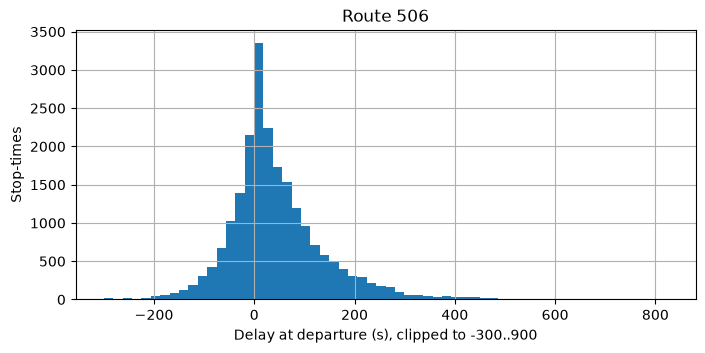

In [73]:
try:
    import matplotlib.pyplot as plt
    ax = df["delay_seconds"].clip(-300, 900).hist(bins=60, figsize=(8, 3.5))
    ax.set_xlabel("Delay at departure (s), clipped to -300..900")
    ax.set_ylabel("Stop-times")
    ax.set_title(f"Route {ROUTE}")
    plt.show()
except ImportError:
    print("matplotlib not installed")